# TUTORIAL: The annular combustor, from model to a real-data digital twin

## 1. The azimuthal thermoacoustic low-order model

The first azimuthal mode pair of an annular combustion chamber is described by
the acoustic pressure

$$
p(\theta, t) = \eta_a(t)\cos\theta + \eta_b(t)\sin\theta,
$$

whose mode amplitudes obey two coupled oscillators with a growth rate $\nu$, a
resistive asymmetry $c_2\beta$, a saturation $\kappa$ and a reactive asymmetry
$(\epsilon, \Theta_\epsilon)$. The balance between $\nu$ and $c_2\beta$ sets the
regime:

- spinning modes: $\nu = 30$, $c_2\beta = 5$
- standing modes: $\nu = 0$, $c_2\beta = 50$
- mixed modes: $\nu = 20$, $c_2\beta = 18$

## The model now lives in `dynamodels`

The model itself, and the tutorial that walks through its mode pair, its phase
space and its azimuthal pressure field, moved to
[`dynamodels`](https://andreanovoa.github.io/dynamodels/), the modelling core
that `romda` builds on:

- **Live tutorial:**
  [The annular combustor](https://andreanovoa.github.io/dynamodels/tutorials/tutorial_annular.html)
  — the mode pair $(\eta_a, \eta_b)$ and its phase space, the pressure at four
  microphones around the annulus, and an animation of the azimuthal pressure
  field.
- **Model reference:**
  [Annular combustor](https://andreanovoa.github.io/dynamodels/models/annular/)
  — the three named regimes (`case=`) and the full API.

Sections 2 and 3 below explore the experimental data and assimilate it into this
model, which is what `romda` adds on top.

`romda.models.physical` re-exports the `dynamodels` models, so existing code
keeps working unchanged:

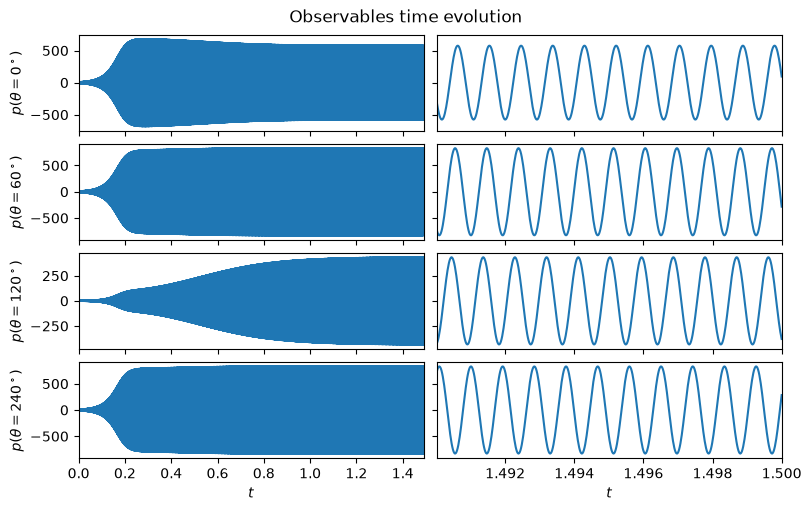

In [1]:
from romda.models.physical import Annular

case = Annular(nu=20., c2beta=18.)  # the mixed mode

state, t_ = case.time_integrate(int(case.t_transient * 3 / case.dt))
case.update_history(state, t_)
case.visualize_observable_hist()

## 2. Real thermoacoustic data from an annular combustor

The experiments are those of
[Indlekofer et al. (2022)](https://doi.org/10.1017/jfm.2022.468) on a
hydrogen-based annular combustor.

In [2]:
from romda.models.physical import Annular
from romda.utils import *

data_folder, results_folder, figs_folder = set_working_directories('annular/')

get_annular_data(data_folder) # Download the data if not already present


File 'annular_data.zip' already exists. Skipping download.
File 'README.md' already exists. Skipping download.




The data available in data_folder are acoustic pressure measurements at the azimuthal locations $ \theta = 0^\circ, 60^\circ, 120^\circ, 240^\circ.$
 
Each .mat data file represents an experiment at different equivalence ratios $\Phi = 0.4875, ..., 0.5750$ (by steps of $0.0125$); and the file includes the variables
- y_raw: raw acoustic pressure recordings 
- y_filtered: post-processed acoustic pressure (mean offset correction and bandpass filter)
- t: timestamp of the recordings


In [3]:

# Define .mat file names and equivalence ratios
ERs = 0.4875 + np.arange(0, 4) * 0.025
files = [data_folder + 'ER_{}.mat'.format(ER) for ER in ERs]



Using the functions "nu_from_ER" and "c2beta_from_ER" we can compute fore each equivalence ratio the linear growth rate $\nu$ and the asymmetry parameter group $c_2\beta$, which allows us to replicate Fig. 9 in [Indlekofer et al. (2022)](https://doi.org/10.1017/jfm.2022.468).



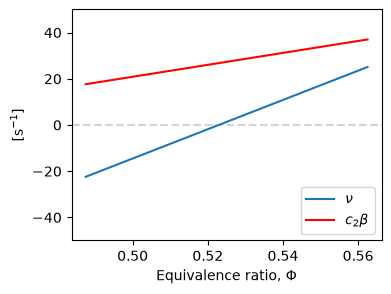

In [4]:
NUs, C2Bs = [], []
for ER in ERs:
    NUs.append(Annular.nu_from_ER(ER))
    C2Bs.append(Annular.c2beta_from_ER(ER))

fig = plt.figure(figsize=(4, 3))
plt.axhline(y=0, color='lightgrey', ls='--')
plt.plot(ERs, NUs, '-', color='C0', label='$\\nu$')
plt.plot(ERs, C2Bs, '-', color='r', label=Annular().alpha_labels['c2beta'])
plt.xlabel(r'Equivalence ratio, $\Phi$')
plt.ylabel('[s$^{-1}$]')
plt.ylim([-50, 50])
plt.legend(loc='lower right');



Let's visualize the power spectral density (PSD) of the acoustic pressure for each equivalence ratio.

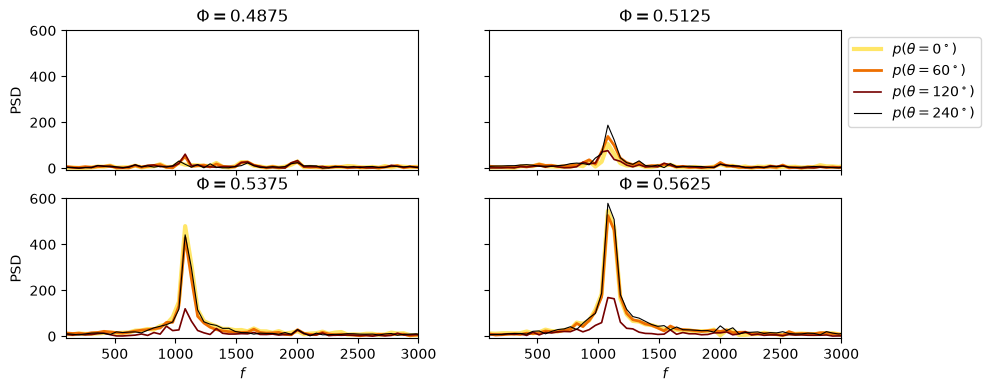

In [5]:
import scipy.io as sio

def fun_PSD(X):
    if X.shape[0] > X.shape[1]:
        X = X.T
    PSD = []
    for x in X:
        yt = np.fft.fft(x)
        PSD.append(2.0 / X.shape[-1] * np.abs(yt[0:X.shape[-1] // 2]))
    return PSD

N, upsample = 1000, 2

fig1 = plt.figure(figsize=(10, 4))
axs = fig1.subplots(2, len(ERs)//2, sharey='all', sharex='all')
for ER, name, ax in zip(ERs, files, axs.ravel()):
    mat = sio.loadmat(name)
    y_raw, t_obs = [mat[key] for key in ['y_raw', 't']]
    y_raw = y_raw[-N::upsample]
    if ER == ERs[0]:
        Nq = y_raw.shape[-1]
        t_obs = t_obs.squeeze()[::upsample]
        dt = t_obs[1]-t_obs[0]
        f = np.linspace(0.0, 1.0 / (2.0 * dt), (N//upsample) // 2)
        colors = plt.cm.afmhot(np.linspace(0,0.7,Nq))[::-1]
        
    psd = fun_PSD(X=y_raw)
    for psd_, c, lw in zip(psd, colors, [3, 2, 1.2, 0.8]):
        ax.plot(f, psd_, color=c, lw=lw)
    ax.set(title='$\\Phi={}$'.format(ER))
    
leg = ['$p(\\theta={}^\\circ)$'.format(deg) for deg in [0, 60, 120, 240]]
axs[0, -1].legend(leg, loc='upper left', bbox_to_anchor=(1, 1))
[ax.set(xlabel='$f$') for ax in axs[1, :]]
[ax.set(ylabel='PSD', xlim=[100, 3000], ylim=[-10, 600]) for ax in axs[:, 0]];


We focus now on a single experiment. We can visualize the instantaneous pressure at each microphone. 
The figure shows how 
1. the post-processed data (i.e., y_filtered) is zero-mean, 
2. the post-processed signals are smoother, and
3. the raw pdfs are wider and more flat.

In [6]:
# Select an equivalence ratio
idx = -1
ER, name = ERs[idx], files[idx]

# Load data
mat = sio.loadmat(name)
y_raw, y_filter, t = [mat[key] for key in ['y_raw', 'y_filtered', 't']]
t = t.squeeze()
Nq = y_raw.shape[-1]


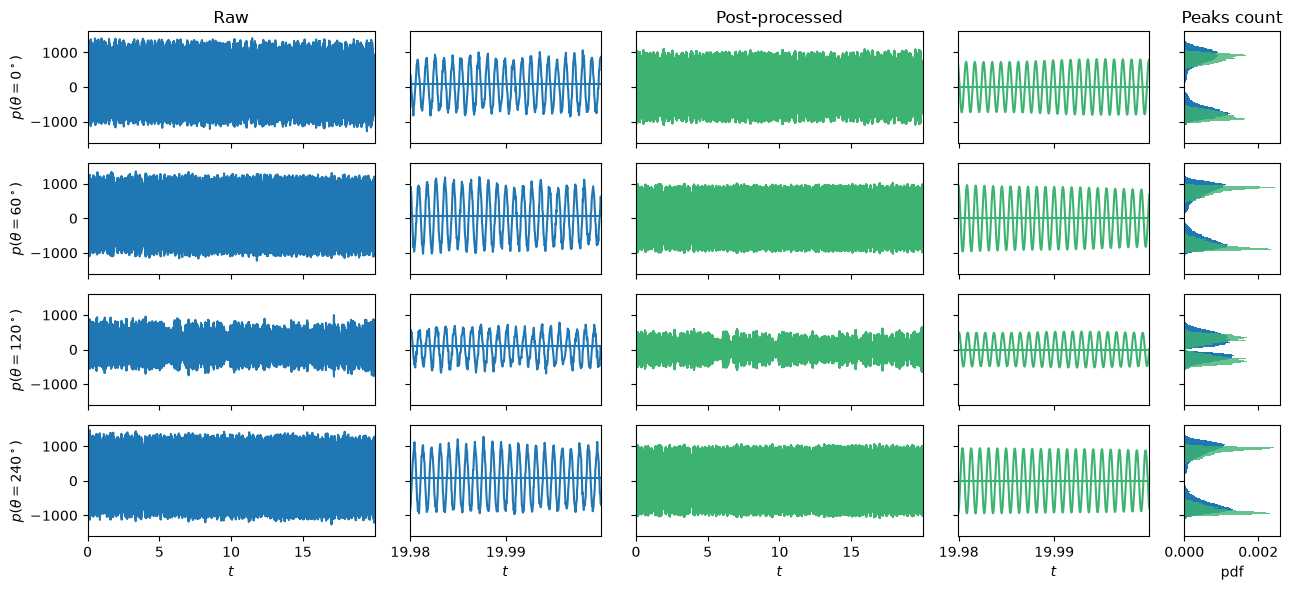

In [7]:

from scipy.signal import find_peaks

upsample = 2
N_max = int(20 / (t[1] - t[0])) 

y_raw_, y_filter_, t_ = [xx[0:N_max:upsample] for xx in [y_raw, y_filter, t]]


fig1 = plt.figure(figsize=(13, 1.5 * Nq), layout="tight")
titles = ['Raw', 'Post-processed']
labels_y = ['$p(\\theta={}^\\circ)$'.format(th) for th in [0, 60, 120, 240]]
cols = ['tab:blue', 'mediumseagreen']

max_y, N_zoom = np.max(y_raw_), int(0.0201 // (t_[1] - t_[0]))
# Plot zoomed timeseries of raw, post-processed and noise
axs = fig1.subplots(Nq, 5, sharex='col', sharey='all', width_ratios=[1.5, 1, 1.5, 1, 0.5])
ax_raw , ax_filter, ax_pdf= axs[:, :2], axs[:, 2:4], axs[:, -1]

for ax, yy, ttl, c in zip([ax_raw, ax_filter], [y_raw_, y_filter_], titles, cols):
    ax[0, 0].set(title=ttl)
    ax[-1, 0].set(xlabel='$t$', xlim=[t_[0], t_[-1]])
    ax[-1, -1].set(xlabel='$t$', xlim=[t_[-N_zoom], t_[-1]])
    for qi in range(Nq):
        ax[qi, 0].plot(t_[:-N_zoom], yy[:-N_zoom, qi], color=c)
        ax[qi, 1].plot(t_[-N_zoom:], yy[-N_zoom:, qi], color=c)
        ax[qi, 1].axhline(np.mean(yy[:, qi]), color=c) 
        if ttl == titles[0]:
            ax[qi, 0].set(ylabel=labels_y[qi])

bins = np.arange(-max_y, max_y + 0.01 * max_y, 0.01 * max_y)
for yy, ttl, c, a in zip([y_raw_, y_filter_], titles, cols, [1, 0.8]):
    ax_pdf[0].set(title='Peaks count')
    ax_pdf[-1].set(xlabel='pdf')
    for qi in range(Nq):
        peaks = find_peaks(abs(yy[:, qi]))[0]
        ax_pdf[qi].hist(yy[peaks, qi], bins=bins, density=True, orientation='horizontal', color=c, alpha=a)


## 3. A real-time digital twin of the annular combustor

We can now put everything we have learned together. Data assimilation using real experimental data

We develop a digital twin of the hydrogen-based annular combustor. We want to estimate the LOM parameters and states from raw experimental data from microphones.  Because the raw data may be biased, we need to model the bias in both, measurement data and model.

The settings of this section are those of [Nóvoa, Noiray, Dawson & Magri (2024)](https://doi.org/10.1017/jfm.2024.1052); the comments in the code cells give the table or the section of the paper that each setting comes from.


### 3.1. Load the data 
Create the reference truth and the observations.



In [8]:
from romda.models.physical import Annular
from romda.observations import Observations
import os

ER = 0.4875 + 0.025 # 0.4875 + np.arange(0, 4) * 0.025

# Assimilation window of the paper (section 6.1): 35 t_CR after the transient, one analysis every 30 time steps
t_start = Annular.t_transient
t_stop = t_start + Annular.t_CR * 35


truth = Observations(model = os.path.join(data_folder, 'ER_{}'.format(ER)),
                     t_start = t_start,
                     t_stop = t_stop,
                     Nt_obs = 30,
                     t_max = t_stop + Annular.t_transient,
                     add_noise = False
                     )


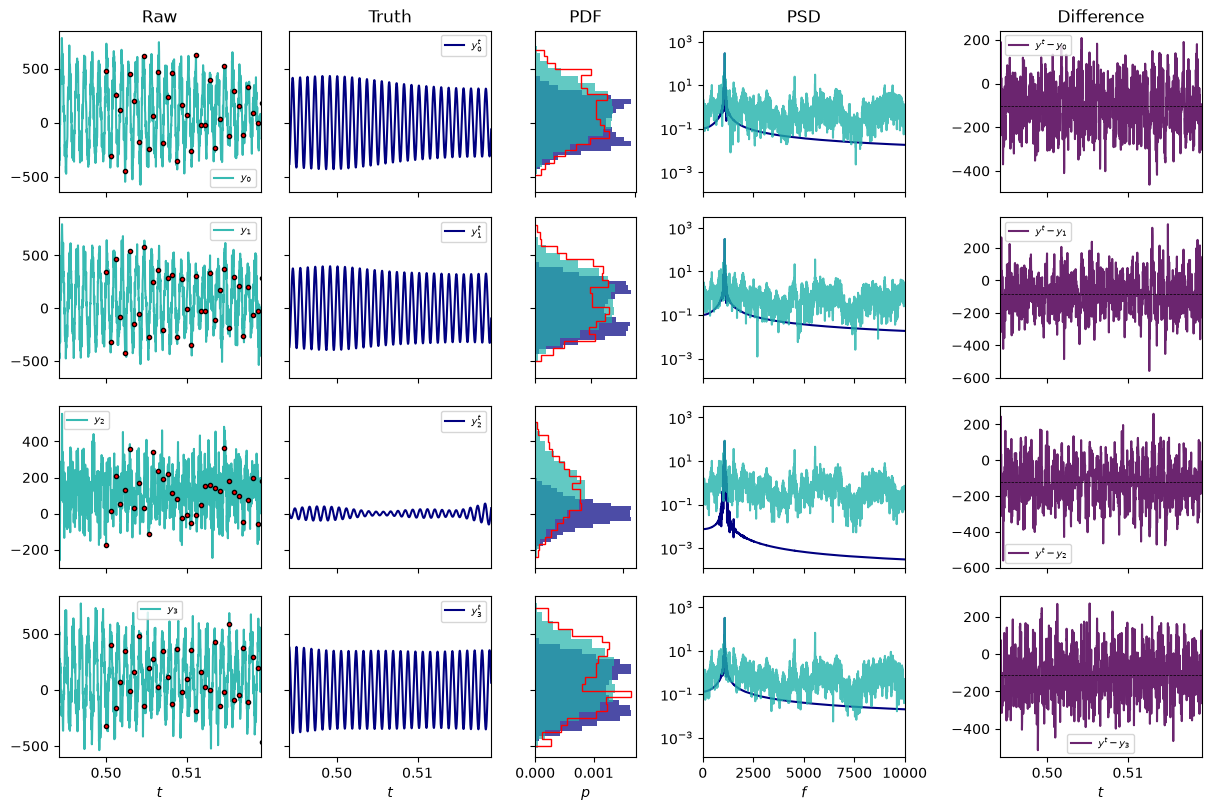

In [9]:
Observations.plot_truth(truth, Nq=4, fig_width=12, window=0.025, f_max=10000)

### 3.2. Define the forecast model
This is the physical model which we will use to model the true data.
Here, we select the filter parameters and write a function that creates the ensemble of a seed: the parameters are drawn uniformly within their initial ranges, and the state about the state that the model with its default parameters reaches after one characteristic time, as `create_ensemble` of the release code of the paper does. The seed sets the initial ensemble and the perturbations of the observations, i.e., the realization of the experiment.

The model is integrated with a fourth-order Runge-Kutta scheme at the sampling interval of the data (`RK4Integrator`). The default integrator of the physical models, scipy's RK45 at its default tolerances, loses the phase of the oscillation within a fraction of the assimilation window, and the filter would absorb this error in the frequency that it infers.


In [10]:
from romda.estimators import rBA_EnKF, EnKF
from romda.run import draw_state_after_spinup
from romda.models import RK4Integrator
import numpy as np

# Initial ranges of the parameters (Table 2 of the paper)
alpha0 = dict(nu=(-10., 30.),
              c2beta=(10, 50),
              kappa=(1.E-4, 2.E-4),
              epsilon=(5e-3, 8e-3),
              omega=(1090 * 2 * np.pi, 1095 * 2 * np.pi),
              theta_b=(0.5, 0.7),
              theta_e=(0.4, 0.6)
              )


def create_ensemble(seed=0, filter_class=rBA_EnKF):
    """The initial ensemble of a seed, for the filter `filter_class`."""
    ensemble = filter_class(parent_model=Annular,
                            dt=truth.dt,
                            seed=seed,
                            m=20,
                            std_phi=0.3,
                            std_alpha=alpha0,
                            distribution_alpha='uniform',
                            inflation=1.001,                   # after each analysis (Table 2)
                            inflation_factor_rejection=1.001,  # and after a rejected analysis
                            )
    model = ensemble.model
    model.integrator.close()
    model.integrator = RK4Integrator(model)

    # The members start about the default model after one t_CR
    reference = Annular(dt=truth.dt)
    reference.integrator = RK4Integrator(reference)
    draw_state_after_spinup(model, reference, spinup_cr=1, std_phi=0.3)
    return ensemble


ensemble = create_ensemble()


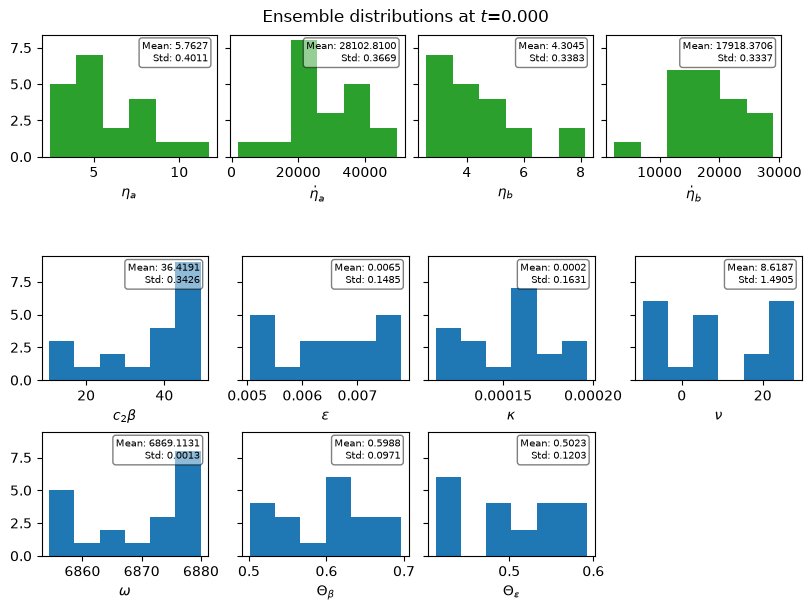

In [11]:
# Visualize ensemble initialization
ensemble.visualize_state(reference_a={'kappa': 1e-4, 'omega': 2 * np.pi, 'epsilon': 1e-3})

### 3.3. Train an ESN to model the model bias
The procedure is the following

&emsp; i. Initialise ESN Bias class object
&emsp; ii. Create synthetic bias to use as training data 
&emsp; iii. Train the ESN

<br>

The training data follow Appendix C of the paper. The model is run for several sets of parameters within their initial ranges; each run is aligned with the data of the start of the record, before the assimilation window, by the lag of smallest distance; and the differences between the data and the runs train the network. The input of the network is the innovation (the raw data minus the model), and its output is the innovation and the model bias (the post-processed data minus the model).

**4.1. Initialise the ESN**

Loaded file is invalid: <class 'bool'>: False
Creating training data for bias model...




 Preparing reference data for training...
y_model_L shape: (11094, 4, 50)
Training ESN model...


src/romda/models/data_driven/rnns/esn_config.py:401: UserWarning: ESN_model: unknown keyword(s) ['L', 'augment_data_length', 'biased_observations', 'keep_fixed_points', 'lag_criterion', 'std_alpha', 'training_record', 'y_model'] ignored
  model = ESN_model(data=data, **kwargs)


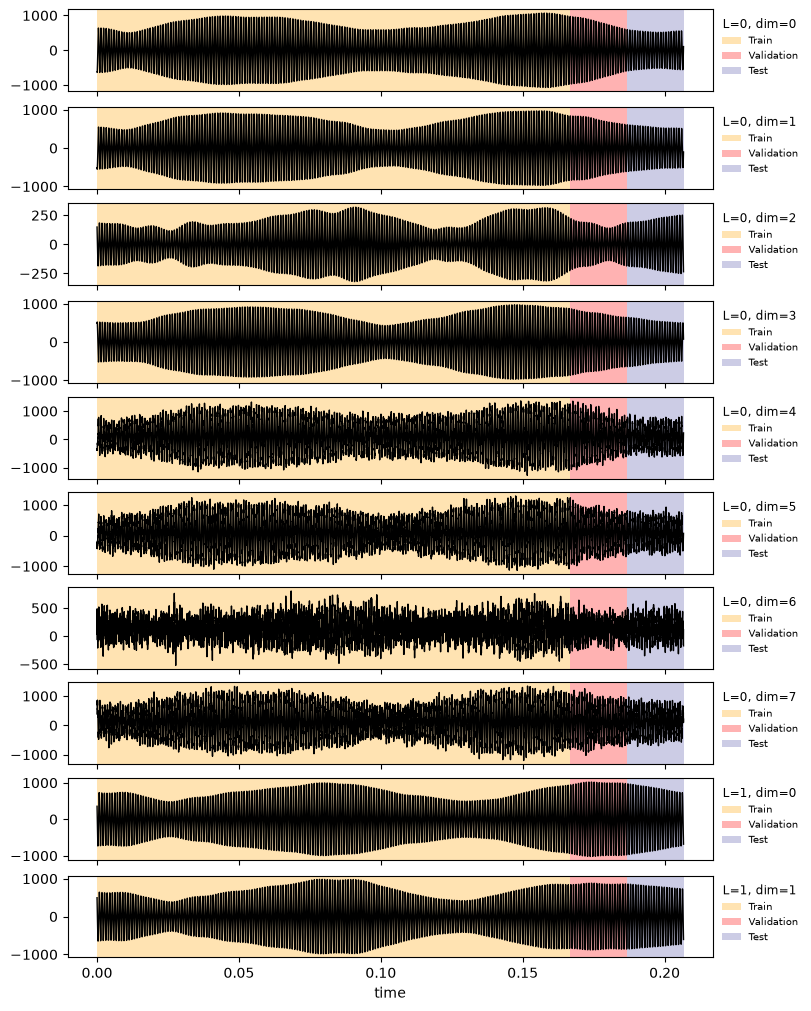

src/romda/models/data_driven/rnns/esn.py:191: UserWarning: ESN_model.train: keyword(s) ['L', 'augment_data_length', 'biased_observations', 'keep_fixed_points', 'lag_criterion', 'std_alpha', 'training_record', 'y_model'] are not attributes of the network and are ignored (did you mean 'est_alpha' for 'std_alpha'?)
  self.train(train_data=data, plot_training=plot_training, **kwargs)


src/romda/models/data_driven/rnns/esn.py:212: UserWarning: ESN_model: keyword(s) ['L', 'augment_data_length', 'biased_observations', 'keep_fixed_points', 'lag_criterion', 'std_alpha', 'training_record', 'y_model'] are not attributes of the model and are ignored
  Model.__init__(self,


Configuration saved to ...results/esn_configs/d154191c854c148e/esn_config.yaml


Trained matrices saved to ...results/esn_configs/d154191c854c148e/trained_matrices.npz


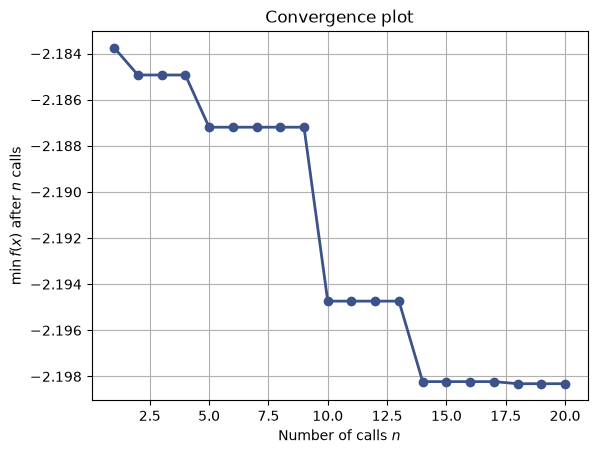

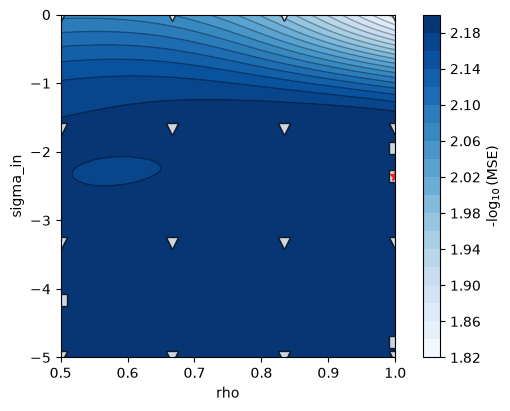

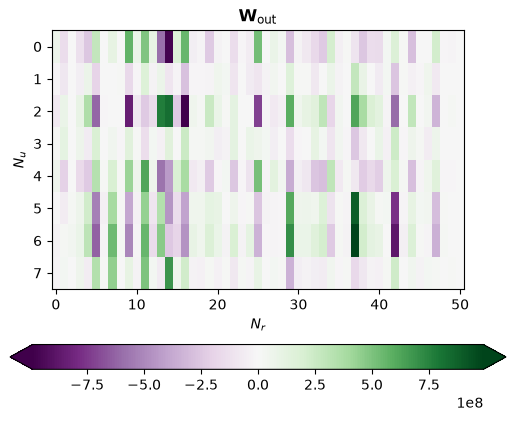

In [12]:
from romda.bias_estimators import ESN_bias
import numpy as np

training_data_filename = f'{results_folder}/ESN_train_data_annular_paper_ER_{ER}'

bias_estimator = ESN_bias(rom=ensemble.model,
                          reference_data=truth,
                          training_data_filename=training_data_filename,
                          upsample=5,
                          N_units=50,
                          N_wash=10,
                          t_train=ensemble.model.t_transient / 3.,
                          t_test=ensemble.model.t_CR * 2,
                          t_val=ensemble.model.t_CR * 2,
                          # Training data generation options (Appendix C of the paper)
                          augment_data=True,
                          biased_observations=True,
                          correlation_based_training=True,
                          training_record='start',     # the start of the record, before the assimilation
                          lag_criterion='distance',    # each run is aligned with the data by the closest lag
                          keep_fixed_points=0.2,       # a fifth of the runs that decay is kept
                          L=50,
                          std_alpha=alpha0,
                          # Network and hyperparameter search (Table 2 and Eq. 4.1 of the paper)
                          centre_input=False,          # the input is scaled by its range only
                          validation_metric='log_nMSE',
                          noise=1e-10,
                          N_folds=4,
                          N_grid=4,
                          N_func_evals=20,
                          rho_range=(0.5, 1.),
                          sigma_in_range=(np.log10(1e-5), np.log10(1e0)),
                          tikh_range=[1e-12, 1e-9],
                          N_ens=ensemble.m,
                          )



**4.2 Create training data**

The details of the code inside ```create_bias_training_dataset()``` function is explained in the tutorial ```Class_Bias.ipynb```.

**4.3. Train the ESN**

The figures above show the training data, the convergence of the hyperparameter search and the output weights of the trained network.

**4.4. Start of the network**

The network starts from reservoir states of its validation data, and the analyses synchronize it with the innovations: no data before the first observation are needed. The paper instead synchronizes the network on the innovations of the ```N_wash``` network steps before the first analysis (the washout); ```run_da_loop(ensemble, truth, washout=True)``` does so.


### 3.4. Apply data assimilation
We now have all the ingredients to start our data assimilation algorithm. The function `assimilate` runs one realization of the experiment: it creates the ensemble of a seed, attaches the bias estimator to it (the EnKF has none), and alternates forecast and analysis steps over the observations. After the last observation, the ensemble forecasts without data.


In [13]:
import contextlib
import io
from romda.observations import variance_fraction_covariance

# Observation error covariance of the paper (section 3.1): 0.1 max|d|^2, the same for every microphone
Cdd = variance_fraction_covariance(truth, 0.1, identical=True)


def assimilate(seed=0, regularization_factor=None, da_method=None):
    """One realization: the regularized bias-aware EnKF with the bias estimator of section 3.3, or the EnKF
    without a bias estimator (da_method='EnKF')."""
    if da_method == 'EnKF':
        ens = create_ensemble(seed, EnKF)
    else:
        ens = create_ensemble(seed, rBA_EnKF)
        ens.bias = bias_estimator.copy()
        ens.regularization_factor = regularization_factor

    with contextlib.redirect_stdout(io.StringIO()):     # the filter prints a line for every rejected analysis
        for d, t_d in zip(truth.y_obs, truth.t_obs):
            ens.forecast_step(t_end=t_d)
            ens.analysis_step(d=d, Cdd=Cdd.copy())
        ens.forecast_step(t_end=truth.t_obs[-1] + 5 * ens.model.t_CR, close=True)
    return ens


### 3.5. One realization
We run the regularized bias-aware EnKF on one seed, with the regularization factor of the paper, 5. The figures show the acoustic pressure of the model estimate and of the bias-corrected estimate against the data, during and after the assimilation, and the bias that the echo state network estimates against the innovations. With a good analysis, the bias-corrected estimate follows the data and the bias stays small.

In [ ]:
ens = assimilate(seed=0, regularization_factor=5.)
ens.visualize_history(truth=truth, plot_members=False, dims=[0, 1])
ens.bias.visualize_bias_and_innovations(plot_members=True)
plt.show()